In [1]:
# Import Libraries
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Dataset
df = pd.read_csv(
    r'C:\Users\sunda\OneDrive\Desktop\Python_works\job_postings_flat.csv'
)

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_skills'] = df['job_skills'].apply(
    lambda x: ast.literal_eval(x) if pd.notna(x) else []
)


In [2]:
df_DA_fin = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'Finland')].copy()

# Drop NaN values from the 'salary_year_avg' column for accurate visualization
df_DA_fin = df_DA_fin.dropna(subset=['salary_year_avg'])

df_DA_fin_exploded = df_DA_fin.explode('job_skills')

df_DA_fin_exploded[['salary_year_avg', 'job_skills']].head(5)

,salary_year_avg,job_skills
52072,105650.0,sql
52072,105650.0,looker
52072,105650.0,tableau
144543,165000.0,go
144543,165000.0,azure


In [3]:
# using df_DA find the count of skills and also the median salary for each skill
df_DA_skills = df_DA_fin_exploded.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by='count', ascending=False)

df_DA_skills = df_DA_skills.rename(columns={'count': 'skill_count', 'median': 'median_salary'})

DA_job_count = len(df_DA_fin)  # Find count of Data Analyst jobs in US with salary info

df_DA_skills['skill_percent'] = df_DA_skills['skill_count'] / DA_job_count * 100

df_DA_skills = df_DA_skills[df_DA_skills['skill_count'] > 0]

df_DA_skills

,skill_count,median_salary,skill_percent
job_skills,,,
go,2,145000.00,22.222222
excel,2,79873.75,22.222222
python,2,86861.25,22.222222
looker,2,115325.00,22.222222
azure,1,165000.00,11.111111
alteryx,1,125000.00,11.111111
linux,1,86875.00,11.111111
flow,1,72900.00,11.111111
power bi,1,86847.50,11.111111


In [4]:
# filter for skill limit
skill_limit = 5

df_DA_skills_high_demand = df_DA_skills[df_DA_skills['skill_percent'] > skill_limit]

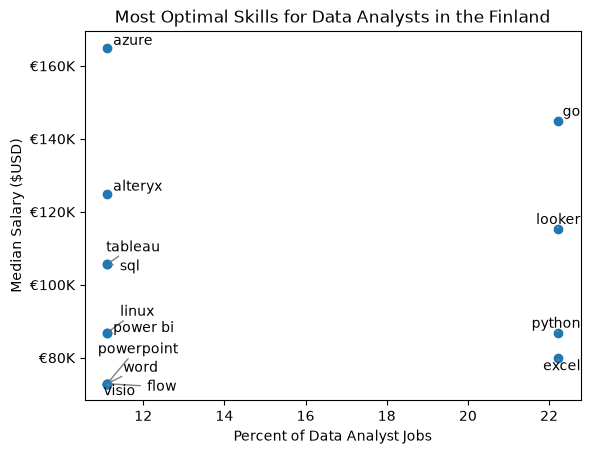

In [ ]:
from adjustText import adjust_text

plt.scatter(df_DA_skills_high_demand['skill_percent'], df_DA_skills_high_demand['median_salary'])
plt.xlabel('Percent of Data Analyst Jobs')
plt.ylabel('Median Salary ($USD)')  # Assuming this is the label you want for y-axis
plt.title('Most Optimal Skills for Data Analysts in Finland')

# Get current axes, set limits, and format axes
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'€{int(y/1000)}K'))  # Example formatting y-axis

# Add labels to points and collect them in a list
texts = []
for i, txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(df_DA_skills_high_demand['skill_percent'].iloc[i], df_DA_skills_high_demand['median_salary'].iloc[i], " " + txt))

# Adjust text to avoid overlap and add arrows
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray'))

plt.show()